In [105]:
# === B1 ===
import os
ROOT = "/content/simuteh-2330511083"
for d in ["data/sintetis", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{ROOT}/{d}", exist_ok=True)
%cd {ROOT}

/content/simuteh-2330511083


In [106]:
%%writefile src/buat_dataset_sintetis.py
"""
buat_dataset_sintetis.py
Membangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.
"""
import os
import csv
import cv2
import numpy as np

SEED = 1083          # 4 digit terakhir NIM 2330511083
N_PER_KELAS = 20
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")
rng = np.random.default_rng(SEED)


def gambar_daun(img, mask):
    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),
                      rng.integers(45, 75)])  # BGR
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    # tulang daun utama dan cabang
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask


def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),
                 int(rng.integers(185, 210))]  # BGR pucat
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)  # tepi cokelat
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun  # bercak hanya di daun


def ganggu_cahaya(img, kondisi):
    """Mensimulasikan kondisi pemotretan di lapangan."""
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)  # separuh teduh
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)  # derau sensor
    return np.clip(f, 0, 255).astype(np.uint8)


def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []
    nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),
                              rng.integers(185, 215)])  # nampan anyaman
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")


if __name__ == "__main__":
    main()

Overwriting src/buat_dataset_sintetis.py


In [107]:
%%writefile src/utils_cv.py
"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""
import cv2
import numpy as np
import matplotlib.pyplot as plt


def baca(path):
    """Membaca citra dan langsung memberi pesan jelas bila gagal."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img


def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd)
        plt.axis("off")
    plt.tight_layout()


def kontras_bercak(kanal, mask_daun, mask_bercak):
    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat."""
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)


def statistik(gray):
    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan_baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}

Overwriting src/utils_cv.py


In [108]:
!python src/buat_dataset_sintetis.py
!ls data/sintetis/citra | wc -l

Selesai: 60 citra tersimpan di data/sintetis
60


In [109]:
%cd /content/simuteh-2330511083/notebook

/content/simuteh-2330511083/notebook


OpenCV 4.14.0 | NumPy 2.1.3 | scikit-image 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 0 247
piksel (y=100, x=200) dalam urutan BGR: [168 202 192]


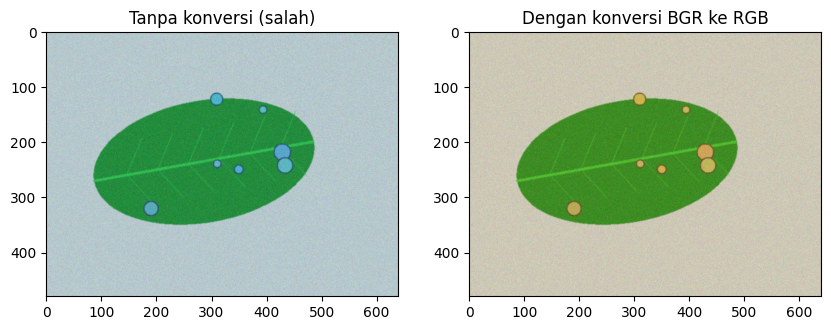

In [110]:
import sys
sys.path.append("../src")

import cv2
import numpy as np
import skimage
import matplotlib.pyplot as plt
from utils_cv import baca

print("OpenCV", cv2.__version__, "| NumPy", np.__version__,
      "| scikit-image", skimage.__version__)
img = baca("../data/sintetis/citra/teh_041.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB")
plt.savefig("../hasil/b1_bgr_rgb.png"); plt.show()

In [111]:
!pip list 2>/dev/null | grep -i opencv
import cv2; print("cv2 yang aktif:", cv2.__version__)

opencv-contrib-python                 4.14.0.94
opencv-python                         5.0.0.93
opencv-python-headless                5.0.0.93
cv2 yang aktif: 4.14.0


In [112]:
%%writefile /content/simuteh-2330511083/requirements.txt
opencv-contrib-python==4.14.0.94
numpy==2.1.3
matplotlib==3.10.0
scikit-image==0.25.2
pandas==2.2.3
pillow==11.3.0

Overwriting /content/simuteh-2330511083/requirements.txt


In [113]:
%cd /content
!zip -rq cadangan_simuteh.zip simuteh-2330511083 -x "*/data/*"
from google.colab import files
files.download("cadangan_simuteh.zip")
%cd /content/simuteh-2330511083/notebook

/content


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/content/simuteh-2330511083/notebook


In [114]:
!ls -lh /content/cadangan_simuteh.zip


-rw-r--r-- 1 root root 7.3M Nov  1 13:51 /content/cadangan_simuteh.zip


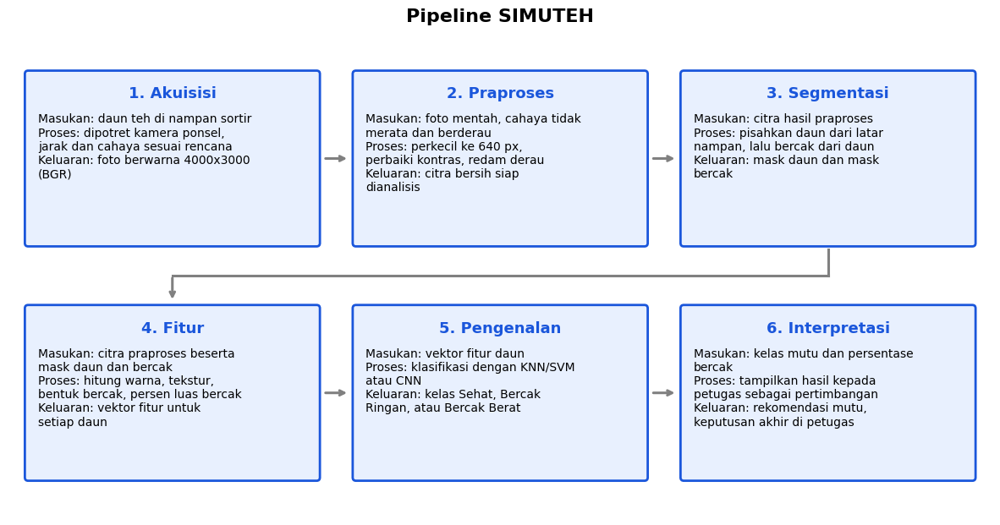

In [115]:
import textwrap
from matplotlib.patches import FancyBboxPatch

tahap = [
    ("1. Akuisisi",
     "Masukan: daun teh di nampan sortir",
     "Proses: dipotret kamera ponsel, jarak dan cahaya sesuai rencana",
     "Keluaran: foto berwarna 4000x3000 (BGR)"),
    ("2. Praproses",
     "Masukan: foto mentah, cahaya tidak merata dan berderau",
     "Proses: perkecil ke 640 px, perbaiki kontras, redam derau",
     "Keluaran: citra bersih siap dianalisis"),
    ("3. Segmentasi",
     "Masukan: citra hasil praproses",
     "Proses: pisahkan daun dari latar nampan, lalu bercak dari daun",
     "Keluaran: mask daun dan mask bercak"),
    ("4. Fitur",
     "Masukan: citra praproses beserta mask daun dan bercak",
     "Proses: hitung warna, tekstur, bentuk bercak, persen luas bercak",
     "Keluaran: vektor fitur untuk setiap daun"),
    ("5. Pengenalan",
     "Masukan: vektor fitur daun",
     "Proses: klasifikasi dengan KNN/SVM atau CNN",
     "Keluaran: kelas Sehat, Bercak Ringan, atau Bercak Berat"),
    ("6. Interpretasi",
     "Masukan: kelas mutu dan persentase bercak",
     "Proses: tampilkan hasil kepada petugas sebagai pertimbangan",
     "Keluaran: rekomendasi mutu, keputusan akhir di petugas"),
]

LB, TG = 4.4, 2.6
pos = [(0.3, 4.2), (5.3, 4.2), (10.3, 4.2),
       (0.3, 0.6), (5.3, 0.6), (10.3, 0.6)]

fig, ax = plt.subplots(figsize=(15, 7.5))
ax.set_xlim(0, 15); ax.set_ylim(0, 7.5); ax.axis("off")
ax.set_title("Pipeline SIMUTEH", fontsize=16, fontweight="bold")

for (judul, m, p, k), (x, y) in zip(tahap, pos):
    ax.add_patch(FancyBboxPatch((x, y), LB, TG, boxstyle="round,pad=0.05",
                                fc="#e8f0fe", ec="#1a56db", lw=2))
    ax.text(x + LB/2, y + TG - 0.3, judul, ha="center", va="center",
            fontsize=13, fontweight="bold", color="#1a56db")
    isi = "\n".join(textwrap.fill(t, 34) for t in (m, p, k))
    ax.text(x + 0.15, y + TG - 0.6, isi, ha="left", va="top", fontsize=10)

def panah(a, b):
    ax.annotate("", xy=b, xytext=a,
                arrowprops=dict(arrowstyle="->", lw=2.2, color="gray"))

panah((0.3 + LB + 0.1, 5.5), (5.3 - 0.1, 5.5))
panah((5.3 + LB + 0.1, 5.5), (10.3 - 0.1, 5.5))
ax.plot([12.5, 12.5], [4.1, 3.7], color="gray", lw=2.2)
ax.plot([12.5, 2.5], [3.7, 3.7], color="gray", lw=2.2)
panah((2.5, 3.7), (2.5, 3.3))
panah((0.3 + LB + 0.1, 1.9), (5.3 - 0.1, 1.9))
panah((5.3 + LB + 0.1, 1.9), (10.3 - 0.1, 1.9))

plt.savefig("../hasil/b1_pipeline.png", dpi=150, bbox_inches="tight")
plt.show()

In [116]:
# === B2 ===
%cd /content/simuteh-2330511083/notebook
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

/content/simuteh-2330511083/notebook


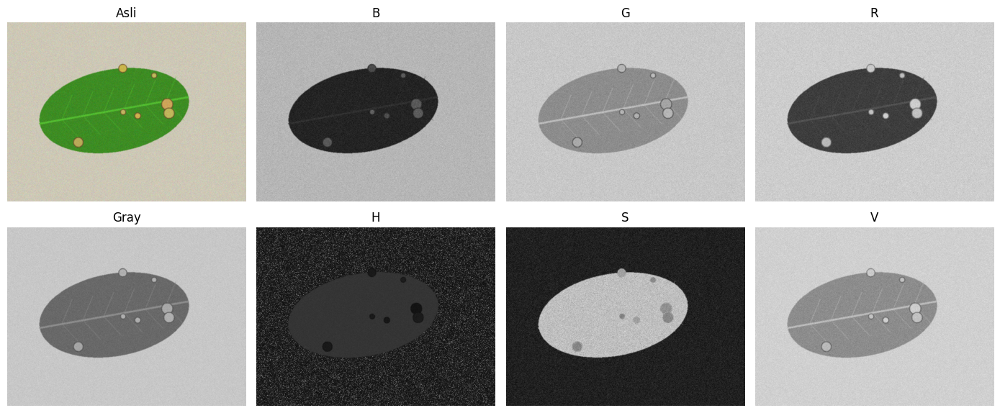

KB kanal B   : 3.64
KB kanal G   : 0.60
KB kanal R   : 9.95
KB kanal Gray: 4.57
KB kanal H   : 8.26
KB kanal S   : 2.47
KB kanal V   : 2.35


In [117]:
nama = "teh_041.png"
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
plt.savefig("../hasil/b2_panel_kanal.png"); plt.show()

for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

fx=0.5: ukuran (240, 320), KB=5.32
fx=0.2: ukuran (96, 128), KB=4.56
fx=0.1: ukuran (48, 64), KB=3.06
fx=0.05: ukuran (24, 32), KB=1.57
k=1: 2 level, KB=3.71
k=2: 3 level, KB=3.72
k=3: 6 level, KB=3.88
k=4: 11 level, KB=4.22
k=8: 154 level, KB=4.57


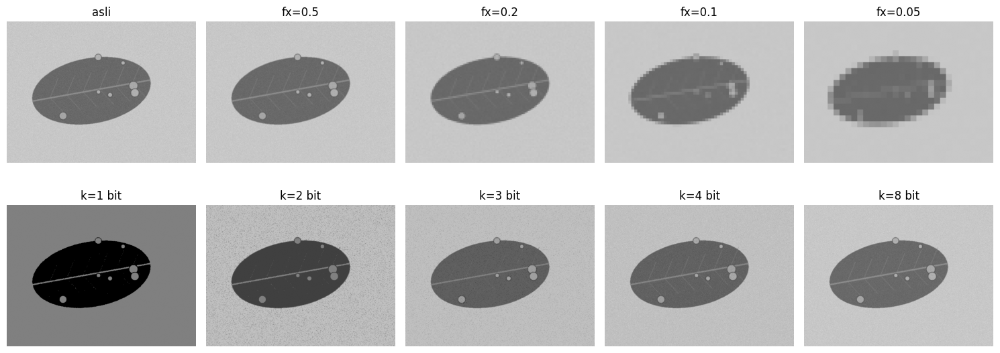

In [118]:
fig, ax = plt.subplots(2, 5, figsize=(15, 6))
ax[0,0].imshow(gray, cmap="gray", vmin=0, vmax=255); ax[0,0].set_title("asli")
for i, fx in enumerate([0.5, 0.2, 0.1, 0.05]):
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")
    ax[0,i+1].imshow(besar, cmap="gray", vmin=0, vmax=255); ax[0,i+1].set_title(f"fx={fx}")

for i, k in enumerate([1, 2, 3, 4, 8]):
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, KB={kontras_bercak(kuant, md, mb):.2f}")
    ax[1,i].imshow(kuant, cmap="gray", vmin=0, vmax=255); ax[1,i].set_title(f"k={k} bit")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig("../hasil/b2_sampling_kuantisasi.png"); plt.show()

In [119]:
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G     R  Gray     H     S     V
kondisi                                                 
bayangan        1.62  0.52  5.34  1.91  4.08  0.92  1.26
gelap           1.32  1.02  9.98  4.09  6.08  0.90  2.79
kontras_rendah  0.93  0.13  4.03  1.98  2.48  0.34  1.09
normal          2.28  0.51  8.55  3.95  6.72  1.56  2.00
terang          1.45  0.66  6.67  3.46  5.13  0.46  1.83


In [120]:
baris = []
for _, d in label[label.kelas == "ringan"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)
tabel_kb_ringan = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb_ringan)
tabel_kb_ringan.to_csv("../hasil/b2_kb_kanal_ringan.csv")

                   B     G     R  Gray     H     S     V
kondisi                                                 
bayangan        0.69  0.36  4.76  1.24  4.97  0.71  0.68
gelap           0.64  0.50  9.87  2.52  7.58  1.00  1.56
kontras_rendah  0.69  0.10  3.42  1.49  2.00  0.24  0.90
normal          1.49  0.84  9.31  3.12  8.83  1.44  1.31
terang          1.35  0.77  6.41  2.57  5.92  1.14  0.89


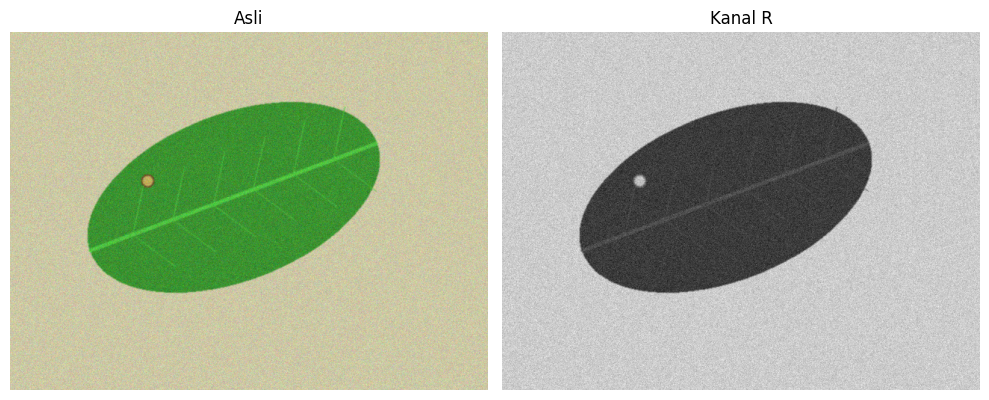

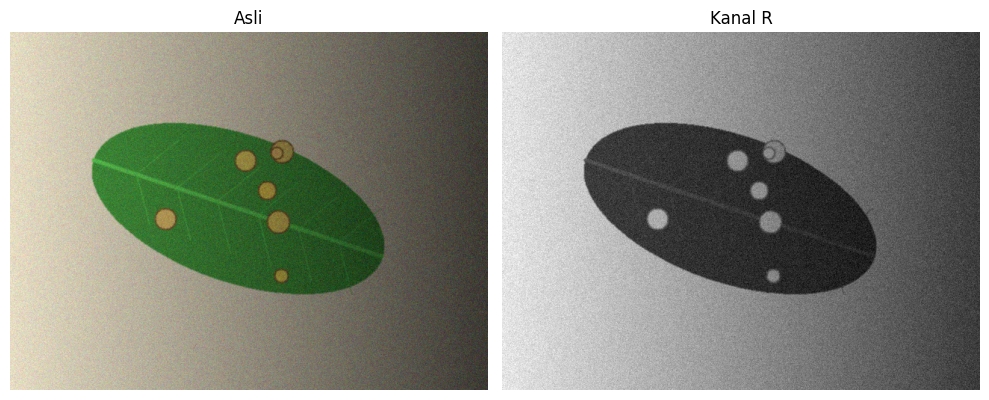

In [121]:
KANAL_TERBAIK = "R"
for nm in ["teh_021.png", "teh_045.png"]:
    im = baca(f"../data/sintetis/citra/{nm}")
    c = semua_kanal(im)[KANAL_TERBAIK]
    tampil([im, c], ["Asli", f"Kanal {KANAL_TERBAIK}"], ukuran=(10, 4))
    plt.savefig(f"../hasil/b2_terbaik_{nm[:-4]}.png"); plt.show()

In [122]:
bercak = np.uint8([[[86, 178, 196]]])
daun   = np.uint8([[[60, 136, 52]]])
for nm, px in {"bercak": bercak, "daun": daun}.items():
    print(nm, "gray:", cv2.cvtColor(px, cv2.COLOR_BGR2GRAY)[0,0],
          "| HSV:", cv2.cvtColor(px, cv2.COLOR_BGR2HSV)[0,0])

bercak gray: 173 | HSV: [ 25 143 196]
daun gray: 102 | HSV: [ 63 158 136]


In [123]:
# === B3 ===
%cd /content/simuteh-2330511083/notebook
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak, statistik

/content/simuteh-2330511083/notebook


teh_041.png {'rerata': 178.5, 'simpangan_baku': 39.2, 'min': 71, 'maks': 225, 'persen_gelap': 0.0, 'persen_terang': 12.3}
teh_042.png {'rerata': 136.6, 'simpangan_baku': 50.3, 'min': 6, 'maks': 202, 'persen_gelap': 15.6, 'persen_terang': 0.0}
teh_043.png {'rerata': 209.3, 'simpangan_baku': 21.9, 'min': 145, 'maks': 246, 'persen_gelap': 0.0, 'persen_terang': 75.3}
teh_044.png {'rerata': 157.7, 'simpangan_baku': 14.0, 'min': 110, 'maks': 190, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 125.8, 'simpangan_baku': 52.8, 'min': 28, 'maks': 243, 'persen_gelap': 1.1, 'persen_terang': 9.5}


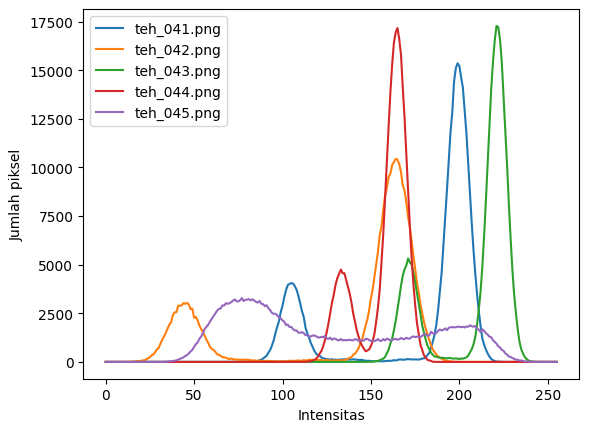

In [124]:
for nama in ["teh_041.png", "teh_042.png", "teh_043.png",
             "teh_044.png", "teh_045.png"]:
    gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"),
                        cv2.COLOR_BGR2GRAY)
    print(nama, statistik(gray))
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend()
plt.savefig("../hasil/b3_histogram_5kondisi.png"); plt.show()

In [125]:
for i in range(21, 26):
    nama = f"teh_{i:03d}.png"
    gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"), cv2.COLOR_BGR2GRAY)
    print(nama, statistik(gray))

teh_021.png {'rerata': 176.9, 'simpangan_baku': 37.4, 'min': 74, 'maks': 236, 'persen_gelap': 0.0, 'persen_terang': 11.2}
teh_022.png {'rerata': 126.7, 'simpangan_baku': 45.7, 'min': 12, 'maks': 193, 'persen_gelap': 15.6, 'persen_terang': 0.0}
teh_023.png {'rerata': 205.6, 'simpangan_baku': 27.0, 'min': 125, 'maks': 252, 'persen_gelap': 0.0, 'persen_terang': 74.1}
teh_024.png {'rerata': 153.1, 'simpangan_baku': 14.4, 'min': 106, 'maks': 190, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_025.png {'rerata': 123.5, 'simpangan_baku': 53.6, 'min': 23, 'maks': 242, 'persen_gelap': 1.9, 'persen_terang': 8.9}


rmin, rmax (persentil 2 dan 98): 53.0 220.0
asli       KB=1.77 sigma=52.8
negatif    KB=1.77 sigma=52.8
cerah+50   KB=1.77 sigma=51.2
kontras    KB=1.77 sigma=74.5
regang     KB=1.83 sigma=80.1
gamma0.5   KB=1.58 sigma=37.7
gamma1.8   KB=2.11 sigma=57.3
ekualisasi KB=1.41 sigma=73.4
CLAHE      KB=2.18 sigma=45.1


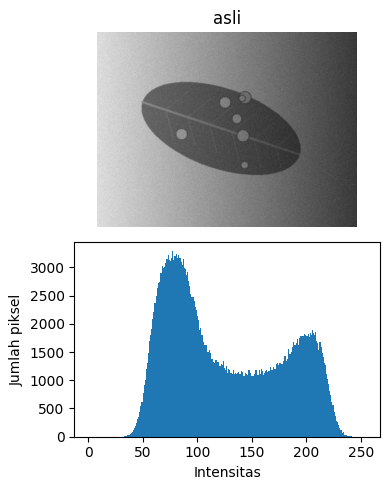

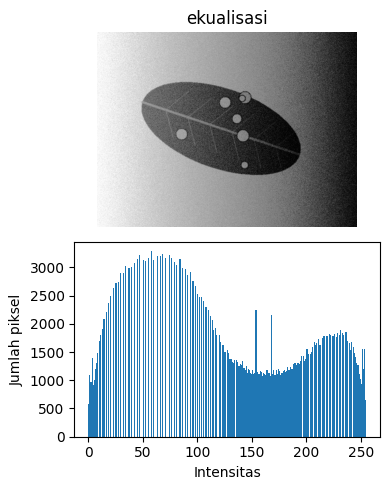

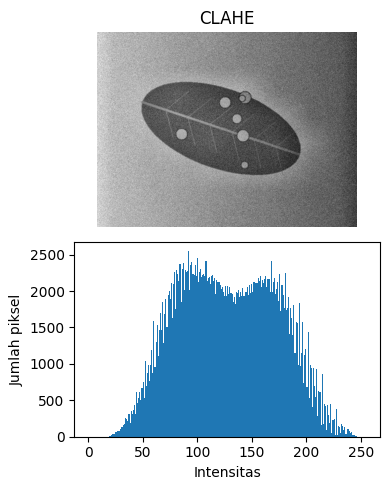

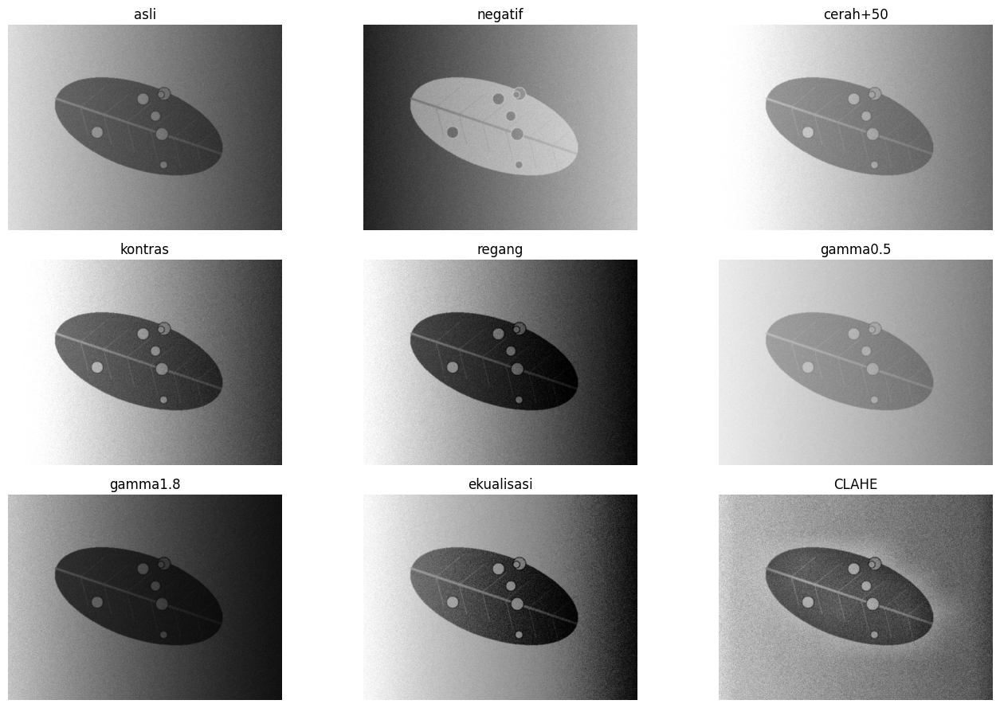

In [126]:
nama = "teh_045.png"
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255, 0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray),
}
print("rmin, rmax (persentil 2 dan 98):", rmin, rmax)
for nm, c in hasil.items():
    print(f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} sigma={c.std():.1f}")

# tampilan citra + histogram (tata letak Gambar 4)
for nm in ["asli", "ekualisasi", "CLAHE"]:
    c = hasil[nm]
    fig, ax = plt.subplots(2, 1, figsize=(4, 5))
    ax[0].imshow(c, cmap="gray", vmin=0, vmax=255); ax[0].axis("off")
    ax[0].set_title(nm)
    ax[1].hist(c.ravel(), bins=256, range=(0, 255))
    ax[1].set_xlabel("Intensitas"); ax[1].set_ylabel("Jumlah piksel")
    plt.tight_layout(); plt.savefig(f"../hasil/b3_{nm}.png"); plt.show()

tampil(list(hasil.values()), list(hasil.keys()), baris=3, ukuran=(14, 9))
plt.savefig("../hasil/b3_panel_metode.png"); plt.show()

clip=1.0 tile=4: KB=2.51
clip=1.0 tile=8: KB=2.31
clip=1.0 tile=16: KB=2.18
clip=2.0 tile=4: KB=2.50
clip=2.0 tile=8: KB=2.18
clip=2.0 tile=16: KB=2.07
clip=4.0 tile=4: KB=2.22
clip=4.0 tile=8: KB=1.85
clip=4.0 tile=16: KB=1.70


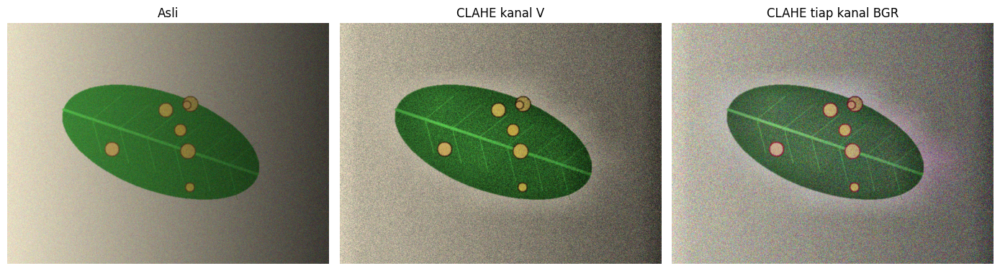

In [127]:
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip,
                            tileGridSize=(tile, tile)).apply(gray)
        print(f"clip={clip} tile={tile}: KB={kontras_bercak(c, md, mb):.2f}")

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"])
plt.savefig("../hasil/b3_clahe_warna.png"); plt.show()

metode          CLAHE  asli  ekualisasi  gamma0.5  gamma0.7  gamma1.5  \
kondisi                                                                 
bayangan         1.58  1.52        1.23      1.36      1.42      1.69   
gelap            1.88  3.45        0.84      2.70      2.98      4.35   
kontras_rendah   1.36  1.74        1.59      1.68      1.70      1.81   
terang           1.34  2.61        1.33      2.46      2.53      2.74   

metode          gamma1.8  regang  
kondisi                           
bayangan            1.78    1.57  
gelap               4.93    3.71  
kontras_rendah      1.82    1.87  
terang              2.82    2.81  

Usulan metode per kondisi: {'bayangan': 'gamma1.8', 'gelap': 'gamma1.8', 'kontras_rendah': 'regang', 'terang': 'gamma1.8'}
gelap           teh_042.png: gamma1.8   KB sebelum=4.33 sesudah=6.23


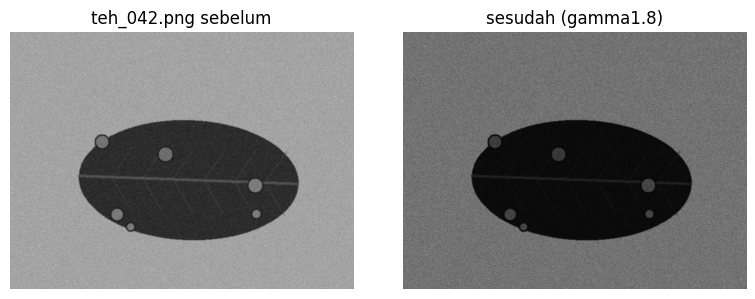

gelap           teh_022.png: gamma1.8   KB sebelum=2.58 sesudah=3.63


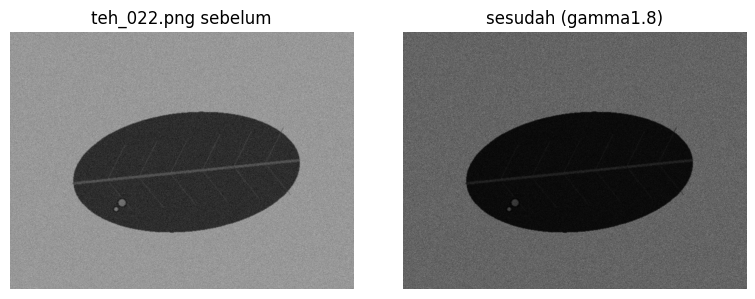

terang          teh_043.png: gamma1.8   KB sebelum=3.39 sesudah=3.66


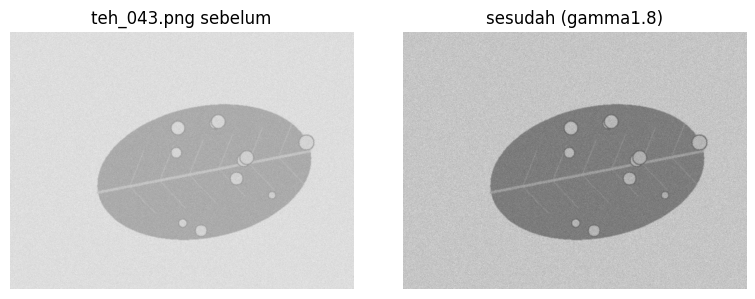

terang          teh_023.png: gamma1.8   KB sebelum=1.82 sesudah=1.99


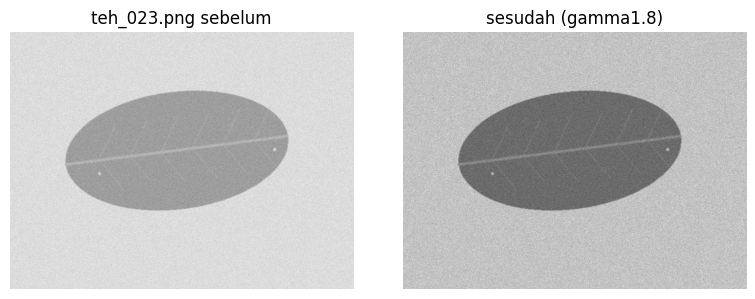

kontras_rendah  teh_044.png: regang     KB sebelum=2.17 sesudah=2.34


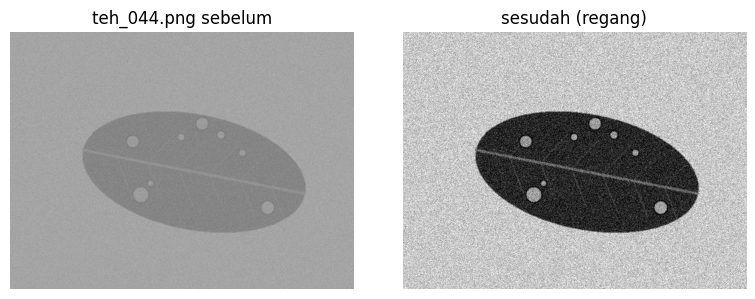

kontras_rendah  teh_024.png: regang     KB sebelum=1.31 sesudah=1.41


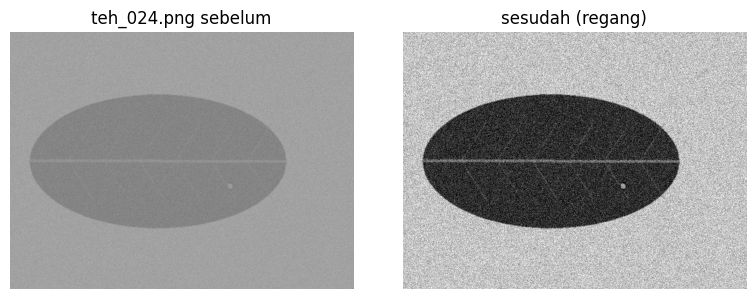

bayangan        teh_045.png: gamma1.8   KB sebelum=1.77 sesudah=2.11


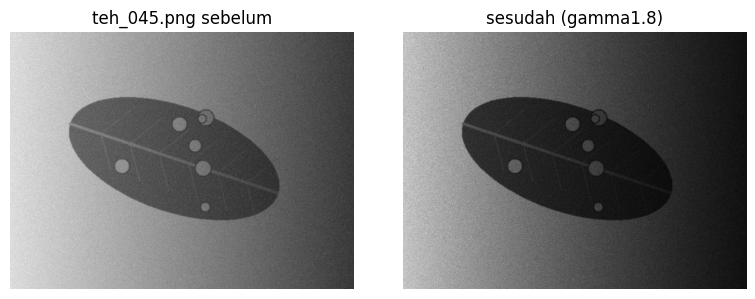

bayangan        teh_025.png: gamma1.8   KB sebelum=1.27 sesudah=1.45


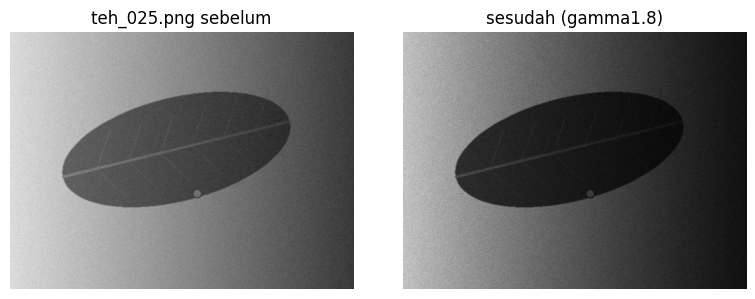

In [128]:
def kandidat(g):
    r1, r2 = np.percentile(g, (2, 98))
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return {"asli": g,
            "gamma0.5": cv2.LUT(g, gamma_lut(0.5)),
            "gamma0.7": cv2.LUT(g, gamma_lut(0.7)),
            "gamma1.5": cv2.LUT(g, gamma_lut(1.5)),
            "gamma1.8": cv2.LUT(g, gamma_lut(1.8)),
            "regang": np.clip((g - r1) / (r2 - r1) * 255, 0, 255).astype(np.uint8),
            "ekualisasi": cv2.equalizeHist(g),
            "CLAHE": clahe.apply(g)}

pasangan = {"gelap": ("teh_042.png", "teh_022.png"),
            "terang": ("teh_043.png", "teh_023.png"),
            "kontras_rendah": ("teh_044.png", "teh_024.png"),
            "bayangan": ("teh_045.png", "teh_025.png")}

# 1) uji semua metode pada 8 citra
baris = []
for kond, (nb, nr) in pasangan.items():
    for nm in (nb, nr):
        im = baca(f"../data/sintetis/citra/{nm}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
        m_b = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
        g0 = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        for met, c in kandidat(g0).items():
            baris.append([kond, nm, met, kontras_bercak(c, m_d, m_b)])
uji = pd.DataFrame(baris, columns=["kondisi", "citra", "metode", "KB"])
uji.pivot_table(index=["kondisi", "citra"], columns="metode",
                values="KB").round(2).to_csv("../hasil/b3_uji_metode.csv")

# 2) rerata KB dua citra per kondisi, lalu usulan metode terbaik (selain "asli")
rata = uji.groupby(["kondisi", "metode"]).KB.mean().unstack().round(2)
print(rata)
PILIHAN = rata.drop(columns="asli").idxmax(axis=1).to_dict()
print("\nUsulan metode per kondisi:", PILIHAN)

# 3) terapkan dan tampilkan sebelum-sesudah
for kond, (nb, nr) in pasangan.items():
    for nm in (nb, nr):
        im = baca(f"../data/sintetis/citra/{nm}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
        m_b = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
        g0 = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        g1 = kandidat(g0)[PILIHAN[kond]]
        print(f"{kond:15s} {nm}: {PILIHAN[kond]:10s} KB sebelum={kontras_bercak(g0, m_d, m_b):.2f} "
              f"sesudah={kontras_bercak(g1, m_d, m_b):.2f}")
        tampil([g0, g1], [f"{nm} sebelum", f"sesudah ({PILIHAN[kond]})"], ukuran=(8, 3))
        plt.savefig(f"../hasil/b3_perbaikan_{kond}_{nm[:-4]}.png"); plt.show()

gelap           teh_042.png: gamma0.5   KB sebelum=4.33 sesudah=3.38


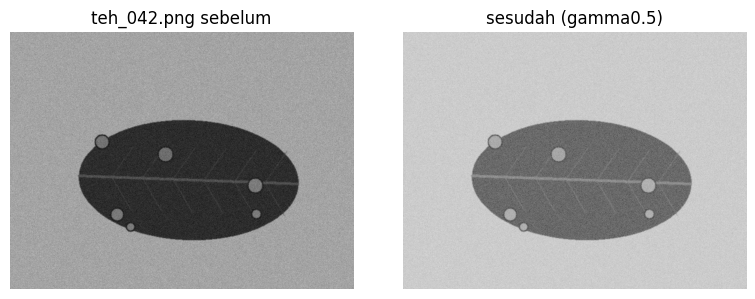

gelap           teh_022.png: gamma0.5   KB sebelum=2.58 sesudah=2.01


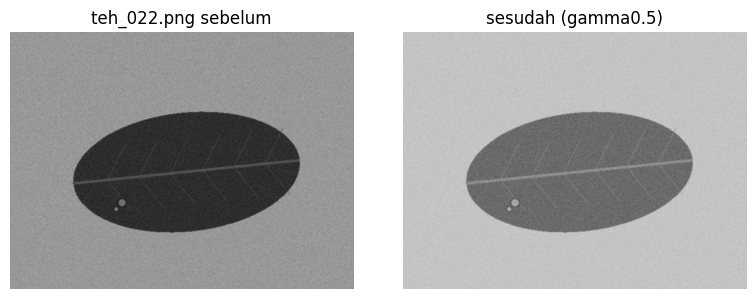

terang          teh_043.png: gamma1.8   KB sebelum=3.39 sesudah=3.66


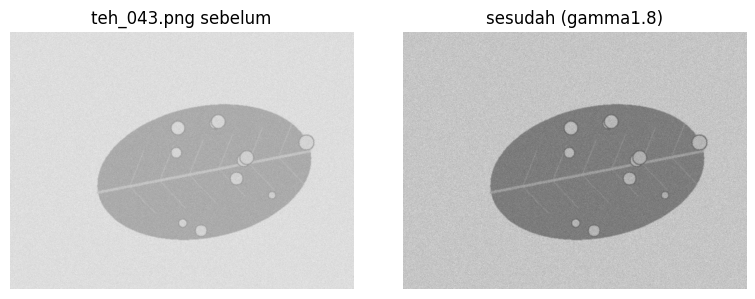

terang          teh_023.png: gamma1.8   KB sebelum=1.82 sesudah=1.99


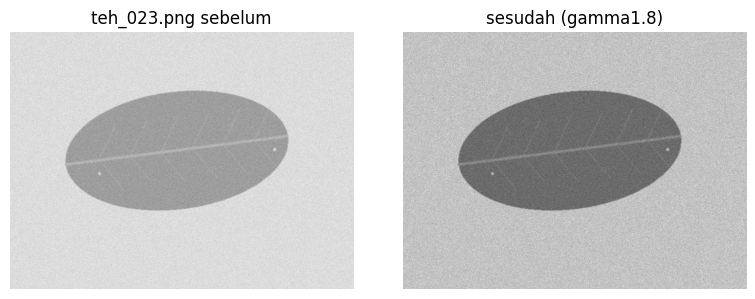

kontras_rendah  teh_044.png: regang     KB sebelum=2.17 sesudah=2.34


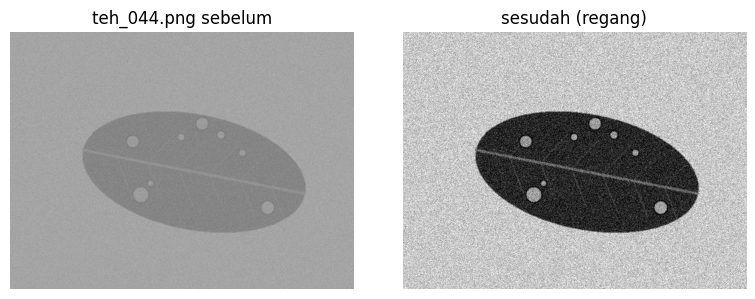

kontras_rendah  teh_024.png: regang     KB sebelum=1.31 sesudah=1.41


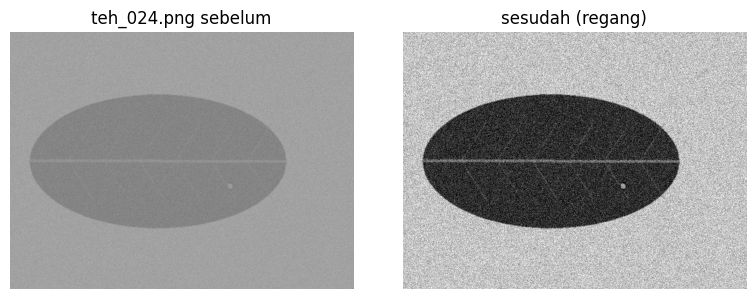

bayangan        teh_045.png: CLAHE      KB sebelum=1.77 sesudah=2.18


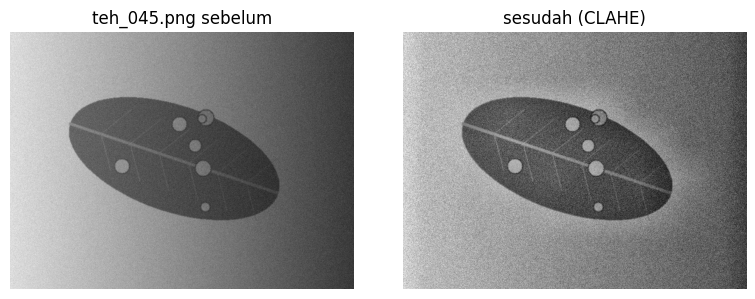

bayangan        teh_025.png: CLAHE      KB sebelum=1.27 sesudah=0.99


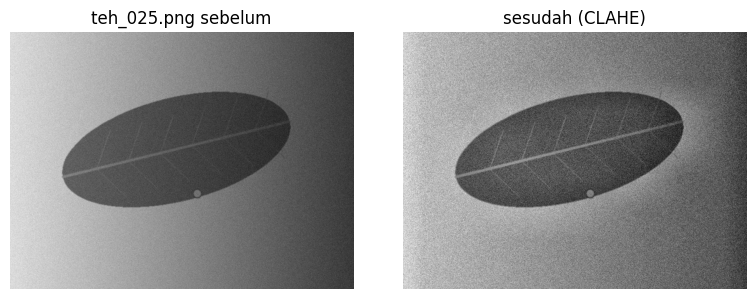

In [129]:
PILIHAN = {"gelap": "gamma0.5", "terang": "gamma1.8",
           "kontras_rendah": "regang", "bayangan": "CLAHE"}

for kond, (nb, nr) in pasangan.items():
    for nm in (nb, nr):
        im = baca(f"../data/sintetis/citra/{nm}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
        m_b = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
        g0 = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        g1 = kandidat(g0)[PILIHAN[kond]]
        print(f"{kond:15s} {nm}: {PILIHAN[kond]:10s} "
              f"KB sebelum={kontras_bercak(g0, m_d, m_b):.2f} "
              f"sesudah={kontras_bercak(g1, m_d, m_b):.2f}")
        tampil([g0, g1], [f"{nm} sebelum", f"sesudah ({PILIHAN[kond]})"], ukuran=(8, 3))
        plt.savefig(f"../hasil/b3_perbaikan_{kond}_{nm[:-4]}.png"); plt.show()

In [130]:
# === B4 ===
%cd /content/simuteh-2330511083/notebook
import sys, time
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

/content/simuteh-2330511083/notebook


In [131]:
def konvolusi(img, k):
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

for nm, k in {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)}.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0
    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=2.153 s, filter2D=0.00052 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=3.502 s, filter2D=0.00050 s


In [132]:
rng = np.random.default_rng(42)
def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)
def derau_sp(img, p):
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out
def ukur_waktu(f, x, ulang=20):
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}

baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d),
                      kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
print(tabel.to_string())
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  3.39
1   gauss_10  rerata_3    36.90      0.13  5.46
2   gauss_10  rerata_5    37.74      0.16  5.62
3   gauss_10   gauss_5    37.74      0.28  5.61
4   gauss_10  median_3    35.51      0.10  5.39
5   gauss_10  median_5    38.39      0.78  6.24
6   gauss_10  median_9    38.62     13.97  7.10
7   gauss_20     tanpa    22.12      0.00  1.96
8   gauss_20  rerata_3    31.44      0.13  4.39
9   gauss_20  rerata_5    34.56      0.16  5.18
10  gauss_20   gauss_5    32.59      0.28  4.70
11  gauss_20  median_3    29.74      0.09  3.93
12  gauss_20  median_5    33.48      0.73  5.05
13  gauss_20  median_9    35.69     15.23  5.83
14  gauss_40     tanpa    16.57      0.00  0.98
15  gauss_40  rerata_3    25.98      0.13  2.70
16  gauss_40  rerata_5    29.84      0.16  3.80
17  gauss_40   gauss_5    27.18      0.29  3.03
18  gauss_40  median_3    23.83      0.10  2.26
19  gauss_40  median_5    27.84      0.7

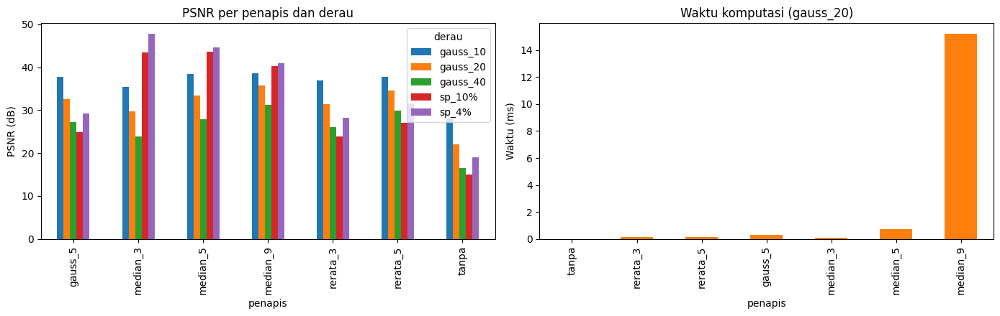

In [133]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
tabel.pivot(index="penapis", columns="derau", values="PSNR_dB").plot.bar(ax=ax[0])
ax[0].set_ylabel("PSNR (dB)"); ax[0].set_title("PSNR per penapis dan derau")
t = tabel[tabel.derau == "gauss_20"].set_index("penapis").waktu_ms
t.plot.bar(ax=ax[1], color="tab:orange")
ax[1].set_ylabel("Waktu (ms)"); ax[1].set_title("Waktu komputasi (gauss_20)")
plt.tight_layout(); plt.savefig("../hasil/b4_grafik_psnr_waktu.png"); plt.show()


           dI    KB
kernel             
1       27.33  4.34
3       27.64  4.45
5       26.50  4.32
9       19.76  3.69
15       8.09  2.15


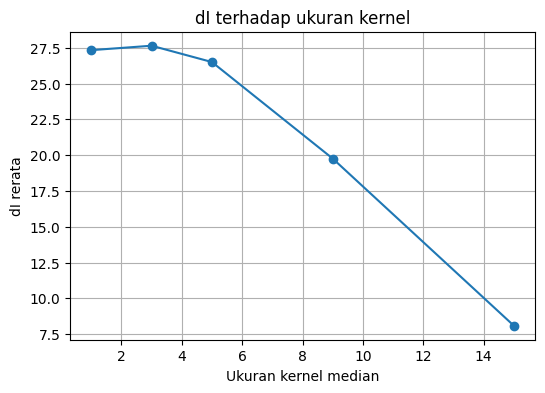

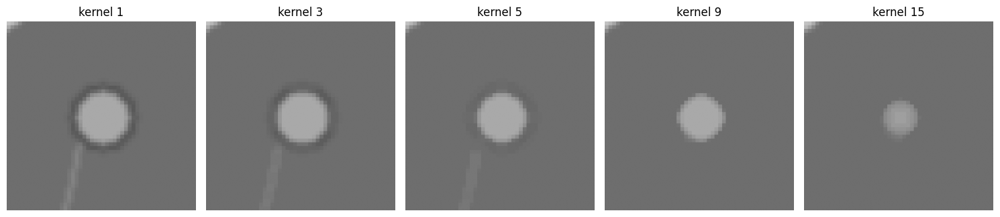

In [134]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
rm = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)
print(rm)
rm.to_csv("../hasil/b4_median_bercak.csv")

plt.figure(figsize=(6, 4)); plt.plot(rm.index, rm.dI, "o-")
plt.xlabel("Ukuran kernel median"); plt.ylabel("dI rerata")
plt.title("dI terhadap ukuran kernel"); plt.grid(True)
plt.savefig("../hasil/b4_dI_kernel.png"); plt.show()

# potongan bercak diperbesar: satu citra ringan, sekitar bercak pertama
nm = "teh_021.png"
g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
ys, xs = np.where(mb2 > 0); cy, cx = int(ys.mean()), int(xs.mean())
y0, y1, x0, x1 = max(cy-25, 0), cy+25, max(cx-25, 0), cx+25
potongan = [cv2.resize((g if k == 1 else cv2.medianBlur(g, k))[y0:y1, x0:x1], None,
            fx=6, fy=6, interpolation=cv2.INTER_NEAREST) for k in [1, 3, 5, 9, 15]]
tampil(potongan, [f"kernel {k}" for k in [1, 3, 5, 9, 15]], ukuran=(15, 3.5))
plt.savefig("../hasil/b4_potongan_bercak.png"); plt.show()

In [135]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy)); B = unsharp(redam(noisy))
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
          f"sigma_latar={A[latar].std():.1f} | redam->tajam "
          f"PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.41 sigma_latar=7.9 | redam->tajam PSNR=30.21 sigma_latar=8.2
Median: tajam->redam PSNR=30.17 sigma_latar=8.1 | redam->tajam PSNR=31.12 sigma_latar=7.2


In [136]:
PENAPIS_PILIHAN = "median_3"  # pilih dari: rerata_3, rerata_5, gauss_5, median_3, median_5, median_9
# alasan pilihan harus berasal dari Tabel 11 dan Sel 4.3 Anda

normal = [f"teh_{i:03d}.png" for i in range(1, 61, 5)]   # 12 citra: 001, 006, 011, ...
baris = []
for nm in normal:
    c = cv2.cvtColor(baca(f"../data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY)
    b0 = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    f = penapis[PENAPIS_PILIHAN]
    baris.append([nm, cv2.PSNR(b0, c), cv2.PSNR(b0, f(c))])
psnr12 = pd.DataFrame(baris, columns=["citra", "PSNR_sebelum", "PSNR_sesudah"]).round(2)
psnr12.loc[len(psnr12)] = ["rerata", psnr12.PSNR_sebelum.mean().round(2), psnr12.PSNR_sesudah.mean().round(2)]
print(psnr12.to_string())
psnr12.to_csv("../hasil/b4_psnr_12_normal.csv", index=False)

          citra  PSNR_sebelum  PSNR_sesudah
0   teh_001.png         32.23         39.41
1   teh_006.png         29.45         36.83
2   teh_011.png         30.76         38.07
3   teh_016.png         32.55         39.66
4   teh_021.png         30.04         37.36
5   teh_026.png         35.74         42.31
6   teh_031.png         35.19         41.97
7   teh_036.png         29.58         36.90
8   teh_041.png         32.45         39.48
9   teh_046.png         29.00         36.35
10  teh_051.png         29.39         36.70
11  teh_056.png         31.29         38.39
12       rerata         31.47         38.62


In [137]:
normal = [f"teh_{i:03d}.png" for i in range(1, 61, 5)]
for p in ["median_3", "median_5", "gauss_5"]:
    s = [cv2.PSNR(cv2.cvtColor(baca(f"../data/sintetis/bersih/{n}"), cv2.COLOR_BGR2GRAY),
                  penapis[p](cv2.cvtColor(baca(f"../data/sintetis/citra/{n}"), cv2.COLOR_BGR2GRAY)))
         for n in normal]
    print(p, "PSNR rerata 12 citra =", round(np.mean(s), 2))

median_3 PSNR rerata 12 citra = 38.62
median_5 PSNR rerata 12 citra = 41.04
gauss_5 PSNR rerata 12 citra = 40.27


In [138]:
# === B5 ===
%cd /content/simuteh-2330511083/notebook
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

/content/simuteh-2330511083/notebook


In [139]:
%%writefile ../src/praproses.py
"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,        # sampling: lebar citra kerja (piksel)
    "gamma": 1.0,        # < 1 mencerahkan, > 1 menggelapkan
    "clahe_clip": 2.0,   # 0 berarti CLAHE tidak dipakai
    "clahe_tile": 8,
    "penapis": "median", # "none", "rerata", "gaussian", "median"
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,      # 0 berarti tanpa penajaman
}

def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAAN, **(p or {})}

    # 1. Ubah ukuran: lebar = p["lebar"], rasio aspek tetap, INTER_AREA
    h, w = img_bgr.shape[:2]
    tinggi = int(round(h * p["lebar"] / w))
    img = cv2.resize(img_bgr, (p["lebar"], tinggi), interpolation=cv2.INTER_AREA)

    # 2. Koreksi gamma lewat tabel LUT (hanya bila gamma != 1)
    if p["gamma"] != 1:
        lut = np.array([255 * (i / 255) ** p["gamma"] for i in range(256)])
        img = cv2.LUT(img, lut.clip(0, 255).astype(np.uint8))

    # 3. CLAHE hanya pada kanal V (HSV), lalu kembali ke BGR
    if p["clahe_clip"] > 0:
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"],
                                tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    # 4. Redam derau (ukuran kernel harus ganjil)
    k = int(p["kernel"])
    if p["penapis"] == "rerata":
        img = cv2.blur(img, (k, k))
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), p["sigma"])
    elif p["penapis"] == "median":
        img = cv2.medianBlur(img, k)
    # "none": tidak melakukan apa-apa

    # 5. Unsharp masking: citra + k * (citra - blur)
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)

    return img

def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)

Overwriting ../src/praproses.py


In [140]:
import importlib, praproses
importlib.reload(praproses)
from praproses import praproses as pp, simpan_param
img = baca("../data/sintetis/citra/teh_045.png")
out = pp(img, {"penapis": "median", "kernel": 5})
print(out.shape, out.dtype)   # harus (480, 640, 3) uint8

(480, 640, 3) uint8


In [141]:
KANAL = 2   # R (kanal terbaik Bagian 2)
label = pd.read_csv("../data/sintetis/label.csv")
berbercak = label[label.kelas != "sehat"]

konfig = {
    "A: CLAHE2 + median5": {"clahe_clip": 2.0, "penapis": "median", "kernel": 5},
    "B: CLAHE1 + median5": {"clahe_clip": 1.0, "penapis": "median", "kernel": 5},
    "C: tanpa CLAHE + median5": {"clahe_clip": 0, "penapis": "median", "kernel": 5},
}
ringkas = {}
for nk, prm in konfig.items():
    baris = []
    for _, d in berbercak.iterrows():
        im = baca(f"../data/sintetis/citra/{d.nama_file}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
        m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
        o = pp(im, prm)
        baris.append([d.kondisi_cahaya,
                      kontras_bercak(im[:, :, KANAL], m_d, m_b),
                      kontras_bercak(o[:, :, KANAL], m_d, m_b)])
    ev = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"])
    t = ev.groupby("kondisi").mean().round(2)
    t["perubahan_%"] = ((t.KB_sesudah / t.KB_sebelum - 1) * 100).round(1)
    ringkas[nk] = t
    print("\n", nk); print(t)


 A: CLAHE2 + median5
                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
bayangan              5.05        8.86         75.4
gelap                 9.92       18.83         89.8
kontras_rendah        3.72        5.01         34.7
normal                8.93       11.83         32.5
terang                6.54        6.12         -6.4

 B: CLAHE1 + median5
                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
bayangan              5.05        8.65         71.3
gelap                 9.92       19.55         97.1
kontras_rendah        3.72        7.30         96.2
normal                8.93       14.13         58.2
terang                6.54        8.75         33.8

 C: tanpa CLAHE + median5
                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
bayangan              5.05        6.52         29.1
gelap                 9.92       19.39       


Konfigurasi B
                sd_sebelum  sd_sesudah
kondisi                               
bayangan             12.48        7.99
gelap                 9.23        4.80
kontras_rendah       10.78        5.34
normal               12.00        7.26
terang               12.92        7.67

Konfigurasi C
                sd_sebelum  sd_sesudah
kondisi                               
bayangan             12.48        9.27
gelap                 9.23        4.31
kontras_rendah       10.78        3.51
normal               12.00        6.30
terang               12.92        5.79


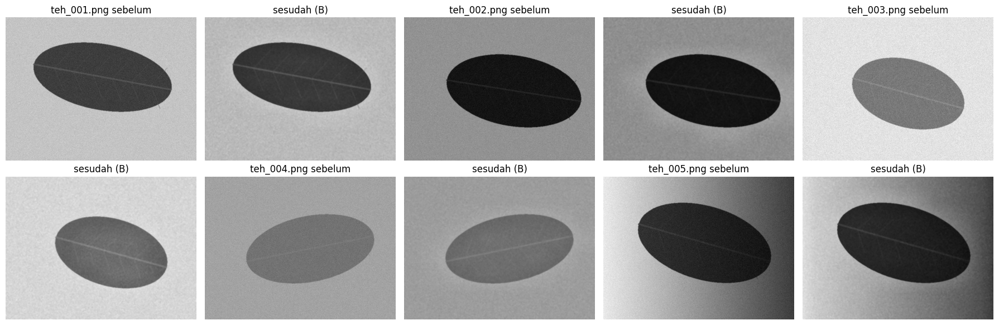

In [142]:
KANAL = 2
label = pd.read_csv("../data/sintetis/label.csv")
kand = {"B": {"clahe_clip": 1.0, "penapis": "median", "kernel": 5},
        "C": {"clahe_clip": 0,   "penapis": "median", "kernel": 5}}

for nk, prm in kand.items():
    baris = []
    for i in range(1, 21):
        nm = f"teh_{i:03d}.png"
        im = baca(f"../data/sintetis/citra/{nm}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
        o = pp(im, prm)
        m_d2 = cv2.resize(m_d, (o.shape[1], o.shape[0]), interpolation=cv2.INTER_NEAREST)
        kond = label.loc[label.nama_file == nm, "kondisi_cahaya"].iloc[0]
        baris.append([kond, im[:, :, KANAL][m_d > 0].std(), o[:, :, KANAL][m_d2 > 0].std()])
    t = (pd.DataFrame(baris, columns=["kondisi", "sd_sebelum", "sd_sesudah"])
         .groupby("kondisi").mean().round(2))
    print("\nKonfigurasi", nk); print(t)
    t.to_csv(f"../hasil/b5_uji_sehat_{nk}.csv")

# panel sebelum-sesudah (konfigurasi B), satu citra sehat per kondisi
daftar, judul = [], []
for nm in ["teh_001.png", "teh_002.png", "teh_003.png", "teh_004.png", "teh_005.png"]:
    im = baca(f"../data/sintetis/citra/{nm}")
    daftar += [im[:, :, KANAL], pp(im, kand["B"])[:, :, KANAL]]
    judul += [f"{nm} sebelum", "sesudah (B)"]
tampil(daftar, judul, baris=2, ukuran=(18, 6))
plt.savefig("../hasil/b5_panel_sehat.png"); plt.show()

In [143]:
param = {"gamma": 1.0, "clahe_clip": 1.0, "penapis": "median", "kernel": 5}
simpan_param(param, "../hasil/param_praproses.json")
print(open("../hasil/param_praproses.json").read())

{
  "lebar": 640,
  "gamma": 1.0,
  "clahe_clip": 1.0,
  "clahe_tile": 8,
  "penapis": "median",
  "kernel": 5,
  "sigma": 1.0,
  "tajam_k": 0.0
}


In [144]:
KANAL = 2
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    o = pp(im, param)
    baris.append([d.kondisi_cahaya, kontras_bercak(im[:, :, KANAL], m_d, m_b),
                  kontras_bercak(o[:, :, KANAL], m_d, m_b)])
t12 = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"]).groupby("kondisi").mean().round(2)
t12["perubahan_%"] = ((t12.KB_sesudah / t12.KB_sebelum - 1) * 100).round(1)
print(t12); t12.to_csv("../hasil/b5_evaluasi.csv")

                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
bayangan              5.05        8.65         71.3
gelap                 9.92       19.55         97.1
kontras_rendah        3.72        7.30         96.2
normal                8.93       14.13         58.2
terang                6.54        8.75         33.8


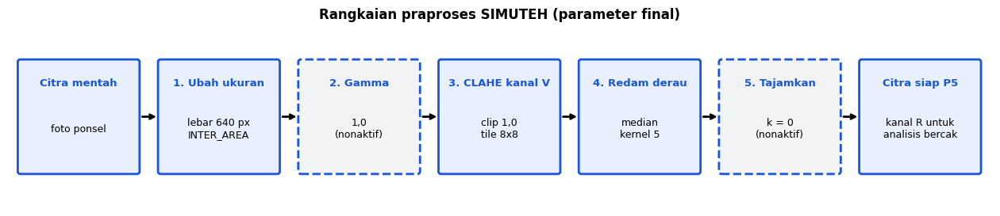

In [145]:
from matplotlib.patches import FancyBboxPatch
langkah = [("Citra mentah", "foto ponsel"),
           ("1. Ubah ukuran", "lebar 640 px\nINTER_AREA"),
           ("2. Gamma", "1,0\n(nonaktif)"),
           ("3. CLAHE kanal V", "clip 1,0\ntile 8x8"),
           ("4. Redam derau", "median\nkernel 5"),
           ("5. Tajamkan", "k = 0\n(nonaktif)"),
           ("Citra siap P5", "kanal R untuk\nanalisis bercak")]
fig, ax = plt.subplots(figsize=(16, 3)); ax.set_xlim(0, 16); ax.set_ylim(0, 3); ax.axis("off")
ax.set_title("Rangkaian praproses SIMUTEH (parameter final)", fontweight="bold")
for i, (j, t) in enumerate(langkah):
    x = 0.2 + i * 2.28
    nonaktif = "nonaktif" in t
    ax.add_patch(FancyBboxPatch((x, 0.6), 1.9, 1.8, boxstyle="round,pad=0.04",
                 fc="#f1f3f4" if nonaktif else "#e8f0fe", ec="#1a56db", lw=2,
                 ls="--" if nonaktif else "-"))
    ax.text(x + 0.95, 2.0, j, ha="center", fontsize=9.5, fontweight="bold", color="#1a56db")
    ax.text(x + 0.95, 1.3, t, ha="center", va="center", fontsize=9)
    if i < len(langkah) - 1:
        ax.annotate("", xy=(x + 2.25, 1.5), xytext=(x + 1.95, 1.5), arrowprops=dict(arrowstyle="->", lw=2))
plt.savefig("../hasil/b5_diagram_praproses.png", dpi=150, bbox_inches="tight"); plt.show()